# Finite receiver: acquisition, accuracy, and retention

How accurately can a finite memory receive the diary's information, and what keeps that information there after the source is disconnected? We follow two receiver designs through acquisition and storage. Their trajectories show what happens in each calculation; the analytic bounds establish how accurately they approximate the ideal transfer throughout the receiving interval.

The 63-site chain is compared through $\Omega T=1$ and the 550-site chain through $\Omega T=2$. The longer receiving interval needs more sites to retain the stated accuracy. Both counts include the source. The pulse receiver is a separate endpoint protocol.

The source site initially carries a diary label. Every site also has a distinct vacuum state. Label-preserving exchange moves every coherent superposition through the same dynamics. Nearest-neighbor locality means that only adjacent chain sites exchange excitations.

## Build the chain

The sites are numbered $0,\ldots,N$, giving $N+1$ sites in total. Site 0 is the source; sites 1 through $N$ form the memory. Each site supports vacuum and $d$ coherent species labels. Nearest-neighbor exchange preserves the label and has coupling

$$
b_n=\Omega\sqrt{n(n+2h-1)},\qquad n=1,\ldots,N.
$$

Here $h$ is the shape parameter and $\Omega$ sets the rate of evolution. Each diary label evolves under the same tridiagonal matrix $K_N$, with zero diagonal and off-diagonal entries $b_n$. An excitation initially at the source has state

$$
u(t)=e^{-iK_Nt}|0\rangle.
$$

For a maximally entangled diary input, the memory's erasure structure gives

$$
r_N(t)=1-|u_0(t)|^2=\frac{I(Q:M)}{2\log d}.
$$

Thus the probability outside the source is also the normalized reference information in memory. Writing $p_0=|u_0|^2$, we compute its derivative directly from the Hamiltonian and use it to obtain activation:

$$
\dot p_0=2\operatorname{Re}\left[u_0^*(-ib_1u_1)\right],\qquad
A_N=-\frac{\dot p_0}{4h\Omega p_0}.
$$

The infinite chain supplies the reference curves,

$$
r_\infty=1-\operatorname{sech}^{4h}(\Omega t),\qquad
A_\infty=\tanh(\Omega t),\qquad s=\frac{\Omega t}{\pi}.
$$

Locality in this implementation means nearest-neighbor adjacency in the chain. Localization of these modes in the original wedge field is a separate physical question.

In [1]:
from pathlib import Path
import os, datetime
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
sys.path.insert(0, str(Path('code').resolve()))
OUTPUT = Path('outputs/runs') / os.environ.get('ODER_RUN_NAME', datetime.datetime.now().strftime('%Y%m%d_%H%M%S')) / 'receiver'
OUTPUT.mkdir(parents=True, exist_ok=True)
pd.set_option('display.precision', 10)

from scipy.linalg import eigh_tridiagonal
from chain_checks import evolution, certified_design_rows, independent_checks, one_case
from pulse_checks import pulse_checks
display(pd.DataFrame(independent_checks().items(),columns=['independent check','error']))
designs=certified_design_rows()
display(pd.DataFrame(designs).drop(columns=['qualification','sampling_interval']))

,independent check,error
0,eigh_vs_dense_expm_l2_error,1.1764367177e-15
1,infinite_schrodinger_equation_finite_differenc...,1.3267742460e-10


,h,Omega,X,N_largest_node,chain_dimension,max_coupling,norm_difference_analytic_bound_E,boundary_forcing_integral,quadrature_reported_error,uniform_retrieval_error_bound,uniform_normalized_activation_error_bound,sampled_max_retrieval_error,sampled_max_normalized_activation_error,endpoint_retrieval,endpoint_exact_retrieval,samples
0,1,1,1.0,62,63,62.4979999680,0.0000002138,0.0000002138,5.6009260869e-18,0.0000004276,0.0000008690,2.7755575616e-15,1.1102230246e-15,0.8236215524,0.8236215524,801
1,1,1,2.0,549,550,549.4997725204,0.0000000401,0.0000000401,2.1262993651e-17,0.0000000803,0.0000009697,2.5535129566e-15,1.0103029524e-14,0.9950084609,0.9950084609,801


## Compare trajectories with uniform error bounds

Truncating the infinite chain removes a boundary link. Duhamel's formula bounds the resulting state error throughout $[0,T]$ by

$$
E_N=b_{N+1}\int_0^T|c_{N+1}(v)|\,dv,
$$

where $c_{N+1}$ is the infinite-chain amplitude at the first omitted site. The code evaluates this integral and its closed form independently. For the designs below, $h=1$ and $X=\Omega T$, giving

$$
E_N=\sqrt{N+1}\tanh^{N+2}X,\qquad g_{\min}=\operatorname{sech}^2X.
$$

The corresponding transfer and activation bounds are

$$
|r_N-r_\infty|\leq2E_N,\qquad
|A_N-A_\infty|\leq\frac{(\sqrt2+2)E_N}{2(g_{\min}-E_N)},
\qquad E_N<g_{\min}.
$$

The decoded erasure channels have diamond distance at most $\min(2,4E_N)$. These analytic bounds apply to the **entire acquisition interval**. The observed discrepancies below are maxima over 801 sampled times, calculated by floating-point diagonalization. They provide a direct check against the bounds; the uniform guarantee comes from the analytic estimates.

The two designs use $h=\Omega=1$ and $(X,N)=(1,62)$ and $(2,549)$, respectively. The table displays both the analytic bounds and the sampled discrepancies.

The paper rounds its upper bounds conservatively. For the 63-site design, the appendix reports an activation bound of $8.690\times10^{-7}$ and the main text uses the looser $8.70\times10^{-7}$. For the 550-site design, the calculated transfer bound is $8.0260747064\times10^{-8}$, rounded upward in the appendix to $8.027\times10^{-8}$. Both designs meet the stated $10^{-6}$ error target.

Activation divides a derivative by the residual source probability. A small population error can therefore produce a larger activation error when that residual becomes small. The two bounds must be checked separately.

,total sites,max coupling / Omega,analytic uniform r bound,analytic uniform A bound,sampled r discrepancy,sampled A discrepancy,endpoint r,norm error
0,63,62.4979999680,0.0000004276,0.0000008690,2.7755575616e-15,1.1102230246e-15,0.8236215524,2.6645352591e-15
1,550,549.4997725204,0.0000000803,0.0000009697,2.5535129566e-15,1.0103029524e-14,0.9950084609,3.7747582837e-15


550-site transfer bound from formula: 8.026074706389e-08 ; appendix: 8.027e-8


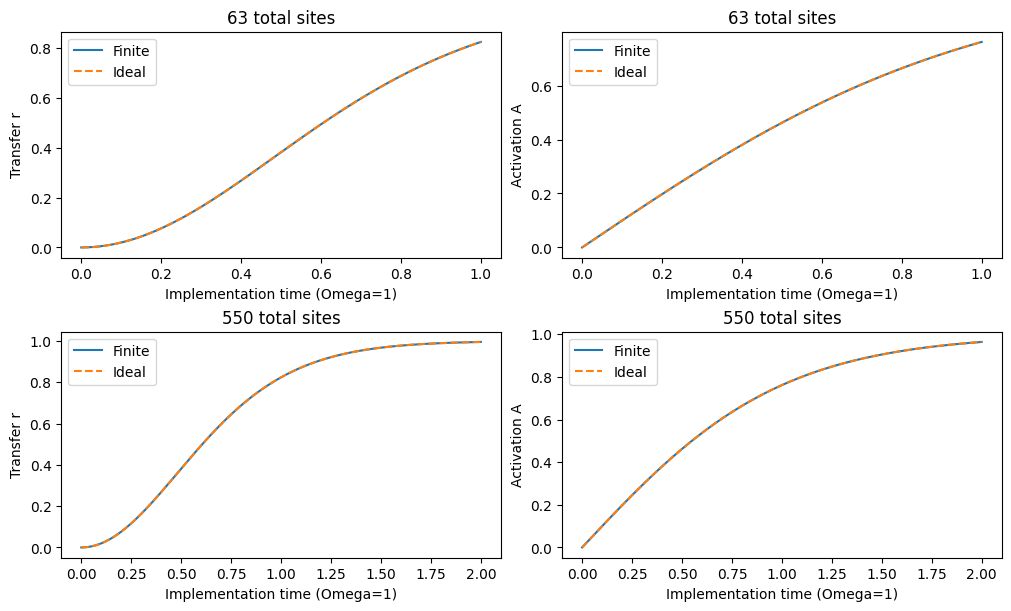

In [2]:
summary=[]; trajectories=[]
for row in designs:
    N=row['N_largest_node']; T=row['X']; h=1.; Omega=1.
    links=Omega*np.sqrt(np.arange(1,N+1)*(np.arange(1,N+1)+2*h-1))
    eigenvalues,eigenvectors=eigh_tridiagonal(np.zeros(N+1),links)
    times=np.linspace(0,T,801)
    state=evolution(eigenvalues,eigenvectors,times)
    norm_error=np.max(abs(np.sum(abs(state)**2,axis=0)-1))
    assert norm_error<1e-11
    residual=abs(state[0])**2
    derivative=2*np.real(state[0].conj()*(-1j*links[0]*state[1]))
    transfer=1-residual; activation=-derivative/(4*h*Omega*residual)
    ideal_r=1-np.cosh(Omega*times)**(-4*h); ideal_a=np.tanh(Omega*times)
    E=row['norm_difference_analytic_bound_E']; gmin=np.cosh(T)**(-2)
    assert E<gmin and np.sqrt(2)*E<2*np.tanh(T)*gmin
    assert derivative.max()<1e-11
    summary.append([N+1,links[-1],2*E,row['uniform_normalized_activation_error_bound'],
        np.max(abs(transfer-ideal_r)),np.max(abs(activation-ideal_a)),transfer[-1],norm_error])
    trajectories.append((times,transfer,activation,ideal_r,ideal_a,state[:,-1],links))
table=pd.DataFrame(summary,columns=['total sites','max coupling / Omega','analytic uniform r bound',
    'analytic uniform A bound','sampled r discrepancy','sampled A discrepancy','endpoint r','norm error'])
display(table);table.to_csv(OUTPUT/'receiver_designs.csv',index=False)
np.testing.assert_allclose(table['endpoint r'],[.823622,.995008],rtol=0,atol=5.1e-7)
assert abs(table['analytic uniform r bound'][0]-4.276e-7)<5.1e-11
assert table['analytic uniform r bound'][1]<8.027e-8
print('550-site transfer bound from formula:',format(table['analytic uniform r bound'][1],'.12e'),'; appendix: 8.027e-8')
np.testing.assert_allclose(table['analytic uniform A bound'],[8.690e-7,9.697e-7],rtol=0,atol=5.1e-11)
fig,axs=plt.subplots(2,2,figsize=(10,6),layout='constrained')
for i,(times,r,a,ri,ai,*_) in enumerate(trajectories):
    axs[i,0].plot(times,r,label='Finite');axs[i,0].plot(times,ri,'--',label='Ideal')
    axs[i,1].plot(times,a,label='Finite');axs[i,1].plot(times,ai,'--',label='Ideal')
    for j in [0,1]:
        axs[i,j].set(xlabel='Implementation time (Omega=1)',ylabel='Transfer r' if j==0 else 'Activation A',
            title=f'{[63,550][i]} total sites');axs[i,j].legend()
fig.savefig(OUTPUT/'finite_receiver_trajectories.png',dpi=180);plt.show()

## Close the acquisition interval and retain the information

At the acquisition deadline $T=X/\Omega$, we set the source–memory link $b_1$ to zero. Internal memory links remain active. The Hamiltonian then separates into source and memory blocks, so lossless, label-independent memory dynamics preserve both memory occupation and $I(Q:M)$. The excitation can continue moving within memory while the acquired information remains there.

The next cell evolves both designs after disconnection. It checks this retention over a further sampled interval. The operation assumes instantaneous disconnection; implementing a finite switch-off requires a corresponding control-error budget.

A maximum available coupling $g_{\max}$ sets the implementation rate and acquisition time:

$$
\Omega\leq\frac{g_{\max}}{\sqrt{N(N+2h-1)}},\qquad
T\geq\frac{X\sqrt{N(N+2h-1)}}{g_{\max}}.
$$

The approximation therefore comes with explicit resource costs. A connected finite chain can exhibit recurrences outside the acquisition interval. Its finite-interval approximation also does not establish global strip-to-disk membership of $A_N$.

`Receiver_and_Storage.ipynb` evaluates a separate finite-switch, lossy receiver. Its target is terminal recovery rather than a uniform approximation to the modular trajectory.

,sites,deadline,retained fraction,sampled retention error
0,63,1.0,0.8236215524,2.9976021665e-15
1,550,2.0,0.9950084609,4.1078251911e-15


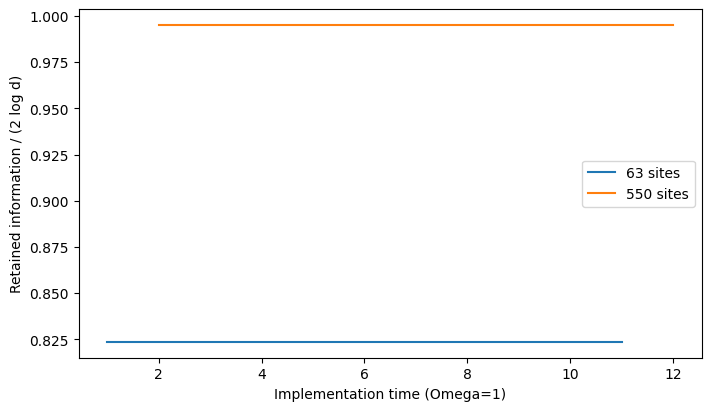

In [3]:
retention=[]
fig,ax=plt.subplots(figsize=(7,4),layout='constrained')
for i,(times,r,a,ri,ai,endpoint,links) in enumerate(trajectories):
    disconnected=links.copy();disconnected[0]=0.
    values,vectors=eigh_tridiagonal(np.zeros(len(endpoint)),disconnected)
    elapsed=np.linspace(0,10,301)
    after=vectors@((vectors.T.conj()@endpoint)[:,None]*np.exp(-1j*values[:,None]*elapsed))
    retained=np.sum(abs(after[1:])**2,axis=0)
    error=np.max(abs(retained-r[-1]))
    assert error<1e-11
    retention.append([len(endpoint),times[-1],r[-1],error])
    ax.plot(times[-1]+elapsed,retained,label=f'{len(endpoint)} sites')
display(pd.DataFrame(retention,columns=['sites','deadline','retained fraction','sampled retention error']))
ax.set(xlabel='Implementation time (Omega=1)',ylabel='Retained information / (2 log d)');ax.legend()
fig.savefig(OUTPUT/'disconnected_retention.png',dpi=180);plt.show()

## Explore other finite chains

The finite-chain routine uses `size` for the total dimension, whereas the manuscript uses $N$ for the largest site index. The cell below evaluates $h=0.5,1,2$, total dimensions 16, 32, 64, and 128, and $\Omega=\pi$.

These checks examine norm conservation and the behavior of smaller chains alongside the preceding quadrature bounds. Recurrences outside a certified acquisition interval are expected in a finite chain.

In [4]:
exploratory=[one_case(h,size) for h in [.5,1.,2.] for size in [16,32,64,128]]
display(pd.DataFrame([{k:r[k] for k in ['h','size','state_norm_error',
    'first_sampled_survival_increase']} for r in exploratory]))

,h,size,state_norm_error,first_sampled_survival_increase
0,0.5,16,1.8873791419e-15,0.9150
1,0.5,32,1.5543122345e-15,1.0850
2,0.5,64,1.8873791419e-15,1.2600
3,0.5,128,1.5543122345e-15,1.4400
4,1.0,16,1.1102230246e-15,0.7250
5,1.0,32,1.2212453271e-15,0.8850
6,1.0,64,1.8873791419e-15,1.0550
7,1.0,128,1.9984014443e-15,1.2325
8,2.0,16,1.1102230246e-15,0.5650
9,2.0,32,1.1102230246e-15,0.7100


## A finite-window pulse receiver

The final calculation considers an effective Markov traveling-field model with a cavity and a coherent downstream buffer. It describes the information retained at the end of a pulse. The roles of its two parameters are important: $u$ labels the prepared pulse, and $t$ is the receiver's operating time.

For $h=\ell=1$, the reference pulse and its dilated preparation are

$$
f(t)=\frac{1}{\sqrt2(1+it)^{3/2}},\qquad
f_u(t)=e^{u/2}f(e^ut).
$$

A rectangular window $[-L,L]$ leaves reference-pulse tail weight

$$
\delta=1-\frac{L}{\sqrt{1+L^2}}.
$$

Let $q_u$ be the accepted norm of the prepared pulse and $I_u=\int_{-L}^L f^*f_u\,dt$ its overlap with the reference pulse in that window. The fixed cavity control is

$$
g(t)=\frac{f^*(t)}{\sqrt{\delta+F(t)}},\qquad
F(t)=\int_{-L}^t|f(v)|^2\,dv.
$$

The cavity's final amplitude is $-I_u$, and the downstream buffer retains $\widetilde r=q_u-|I_u|^2$. Relative to the ideal transfer $r$, the endpoint error obeys $|\widetilde r-r|\leq3\delta$. The normalized hazard with respect to the **preparation parameter** has error bound $6\delta/(p_{\min}-3\delta)$ when the denominator is positive. Here $p_{\min}$ is the minimum ideal residual probability over the preparation interval; on $[0,u]$ it is $\operatorname{sech}^4(u/2)$. This parameter-dependent endpoint comparison is distinct from a retrieval trajectory in operating time.

The quadrature checks use $L=10,100$ and $u=0,1,2,4$. Their error bounds apply within the effective model; a microscopic field-device implementation would require its own error analysis.

In [5]:
pulses=pulse_checks()
display(pd.DataFrame(pulses['rows']))
assert 3*(1-100/np.sqrt(10001))<1.50e-4
pd.DataFrame(pulses['rows']).to_csv(OUTPUT/'pulse_endpoint_checks.csv',index=False)

,L,u,delta,retained_fraction,target_retained_fraction,retained_error,uniform_retained_error_bound,normalized_parameter_hazard,target_activation,activation_error,uniform_activation_bound_to_u
0,10.0,0.0,0.0049628098,0.0049381803,0.0000000000,0.0049381803,0.0148884294,0.0000245678,0.0000000000,0.0000245678,0.0302268897
1,10.0,1.0,0.0049628098,0.3836951462,0.3814999633,0.0021951829,0.0148884294,0.4614508560,0.4621171573,0.0006663012,0.0493311566
2,10.0,2.0,0.0049628098,0.8240933878,0.8236215524,0.0004718354,0.0148884294,0.7613348165,0.7615941560,0.0002593395,0.1843882307
3,10.0,4.0,0.0049628098,0.9950195979,0.9950084609,0.0000111369,0.0148884294,0.9639931898,0.9640275801,0.0000343903,NaN
4,100.0,0.0,0.0000499963,0.0000499938,0.0000000000,0.0000499938,0.0001499888,0.0000000025,0.0000000000,0.0000000025,0.0003000225
5,100.0,1.0,0.0000499963,0.3815221262,0.3814999633,0.0000221629,0.0001499888,0.4621104620,0.4621171573,0.0000066953,0.0004851257
6,100.0,2.0,0.0000499963,0.8236263198,0.8236215524,0.0000047675,0.0001499888,0.7615915526,0.7615941560,0.0000026033,0.0017022081
7,100.0,4.0,0.0000499963,0.9950085736,0.9950084609,0.0000001126,0.0001499888,0.9640272347,0.9640275801,0.0000003454,0.0619589766


## Reading the results

The two finite chains attain the stated transfer fractions, with sampled discrepancies below their analytic uniform bounds. Source disconnection then preserves the acquired information under the specified memory dynamics. Together, the acquisition and retention calculations make the finite receiver's behavior and resource requirements explicit.

The pulse calculation provides a second, endpoint-based approximation. Its accuracy improves as the accepted window and buffer length increase, with the preparation parameter kept distinct from operating time.